# Module 02: Electric Potential Landscape

## Introduction & Learning Objectives
While the electric field $\mathbf{E}(\mathbf{r})$ is a 2D/3D vector field describing force per unit charge, the **electrostatic potential** $V(\mathbf{r})$ is a scalar energy landscape (volts, $\text{V} = \text{J/C}$).

**Learning Objectives:**
1. Compute and visualize the electrostatic scalar potential $V(\mathbf{r})$ for multi-charge distributions.
2. Understand the physical and mathematical distinction between scalar potential $V(\mathbf{r})$ (which is signed and decays as $1/r$) and field magnitude $|\mathbf{E}(\mathbf{r})|$ (which is non-negative and decays as $1/r^2$).
3. Visualize 2D equipotential contours and 3D potential surfaces ("potential hills" around $+q$ and "potential wells" around $-q$).
4. Quantitatively validate the gradient relationship $\mathbf{E}(\mathbf{r}) = -\nabla V(\mathbf{r})$ using second-order finite differences and analyze grid discretization error near singularities.

---

## Physical Model & Equations

With potential reference $V(\infty) = 0$, the scalar potential of $N$ point charges is:

$$V(\mathbf{r}) = \frac{1}{4\pi\varepsilon_0} \sum_{i=1}^{N} \frac{q_i}{\|\mathbf{r} - \mathbf{r}_i\|}$$

And the electric field is recovered via the negative spatial gradient:

$$\mathbf{E}(\mathbf{r}) = -\nabla V(\mathbf{r}) = -\left(\frac{\partial V}{\partial x}\,\hat{\mathbf{x}} + \frac{\partial V}{\partial y}\,\hat{\mathbf{y}}\right)$$

> **Crucial Distinction**: $V(\mathbf{r}) = 0$ does **not** imply $\mathbf{E}(\mathbf{r}) = \mathbf{0}$ (for example, at the midpoint of an electric dipole, $V = 0$ but $|\mathbf{E}|$ is non-zero because $V$ has a steep slope). Conversely, $\mathbf{E}(\mathbf{r}) = \mathbf{0}$ does **not** imply $V(\mathbf{r}) = 0$ (for example, midway between two positive charges $+q$, $\mathbf{E} = \mathbf{0}$ at a saddle point where $V > 0$).

In [1]:
import sys
from pathlib import Path
for _cand in (Path.cwd() / "src", Path.cwd().parent / "src"):
    if _cand.is_dir() and str(_cand.resolve()) not in sys.path:
        sys.path.insert(0, str(_cand.resolve()))

import numpy as np
import matplotlib.pyplot as plt

from invisible_physics import (
    PointCharge,
    apply_scientific_style,
    create_coordinate_grid,
    electric_field_2d,
    electric_potential_2d,
    get_preset_charges,
    numerical_field_from_potential,
    plot_combined_field_and_potential,
    plot_electric_field_streamlines,
    plot_electric_potential_landscape,
    plot_potential_surface_3d,
    validate_potential_gradient_consistency,
)

apply_scientific_style()

---
## 1. Comparing Electric Potential $V(\mathbf{r})$ vs. Field Magnitude $|\mathbf{E}(\mathbf{r})|$

Let us compare a **dipole** ($+1\ \mu\text{C}, -1\ \mu\text{C}$) and **two like positive charges** ($+1\ \mu\text{C}, +1\ \mu\text{C}$) at their respective midpoints $(0, 0)$.

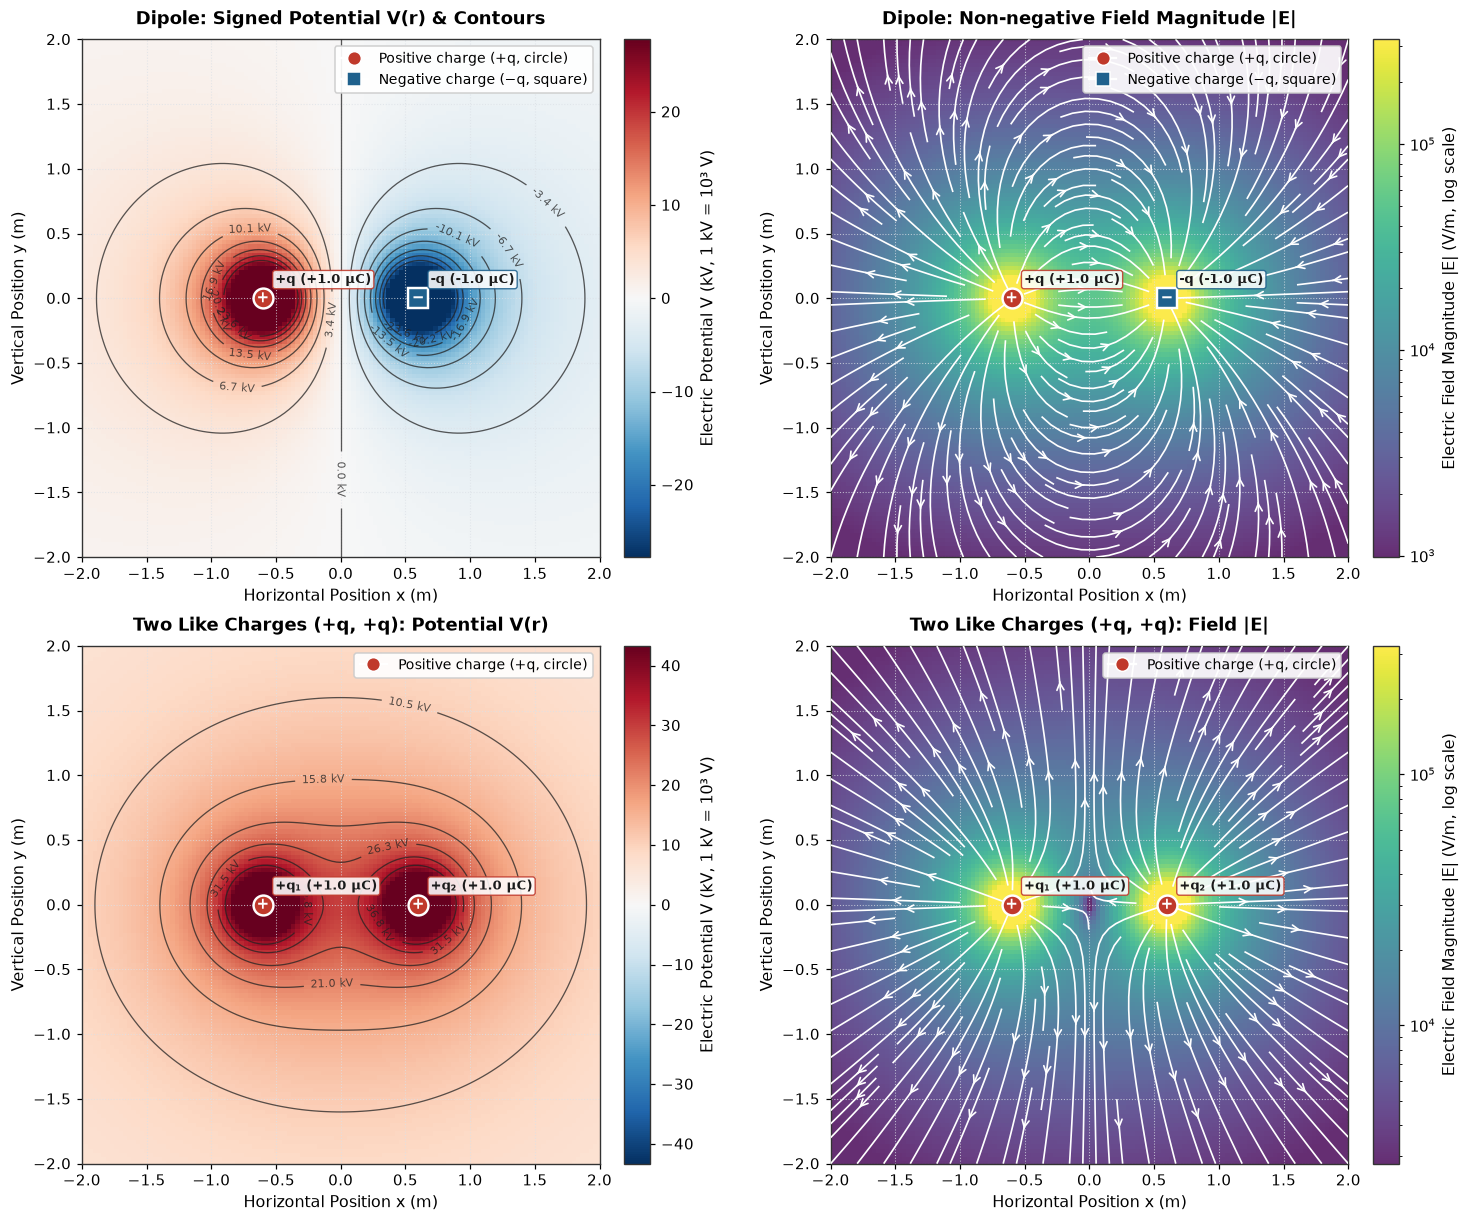

Dipole at origin (0, 0)      -> V =      +0.00 V,  |E| =   49930.84 V/m
Like charges at origin (0,0) -> V =  +29958.51 V,  |E| =       0.00 V/m


In [2]:
X, Y = create_coordinate_grid((-2.0, 2.0), (-2.0, 2.0), n_points=121)

dipole = get_preset_charges("dipole", scale_q_uc=1.0, separation_m=1.2)
like_charges = get_preset_charges("two_like_positive", scale_q_uc=1.0, separation_m=1.2)

v_dip = electric_potential_2d(X, Y, dipole)
f_dip = electric_field_2d(X, Y, dipole)

v_like = electric_potential_2d(X, Y, like_charges)
f_like = electric_field_2d(X, Y, like_charges)

fig, axes = plt.subplots(2, 2, figsize=(13.5, 11.0), constrained_layout=True)
plot_electric_potential_landscape(v_dip, dipole, ax=axes[0, 0], title="Dipole: Signed Potential V(r) & Contours")
plot_electric_field_streamlines(f_dip, dipole, ax=axes[0, 1], title="Dipole: Non-negative Field Magnitude |E|")
plot_electric_potential_landscape(v_like, like_charges, ax=axes[1, 0], title="Two Like Charges (+q, +q): Potential V(r)")
plot_electric_field_streamlines(f_like, like_charges, ax=axes[1, 1], title="Two Like Charges (+q, +q): Field |E|")
plt.show()

mid_idx = (60, 60)  # (x, y) = (0.0, 0.0)
print(f"Dipole at origin (0, 0)      -> V = {v_dip.V[mid_idx]:+10.2f} V,  |E| = {f_dip.E_mag[mid_idx]:10.2f} V/m")
print(f"Like charges at origin (0,0) -> V = {v_like.V[mid_idx]:+10.2f} V,  |E| = {f_like.E_mag[mid_idx]:10.2f} V/m")

### Interpretation
The numerical readout at $(0, 0)$ confirms the physical distinction between potential and field:
- **Dipole at $(0, 0)$**: $V = 0.00\ \text{V}$ (potentials $+k_e q/a$ and $-k_e q/a$ cancel), yet $|\mathbf{E}| = 49,930.84\ \text{V/m}$ because both charges push a positive test charge in the $+x$ direction.
- **Two Like Charges at $(0, 0)$**: $V = +29,958.51\ \text{V}$ (potentials add constructively), yet $|\mathbf{E}| = 0.00\ \text{V/m}$ because $(0, 0)$ is a saddle point where $\nabla V = \mathbf{0}$.

---
## 2. 3D Electrostatic Potential Surfaces

Visualizing $V(x, y)$ as a 3D surface makes it immediately intuitive why positive charges act as **potential hills** and negative charges act as **potential wells**: a positive test charge released on the surface experiences a force $\mathbf{F} = -q_{\text{test}}\nabla V$ directed "downhill" along the steepest descent.

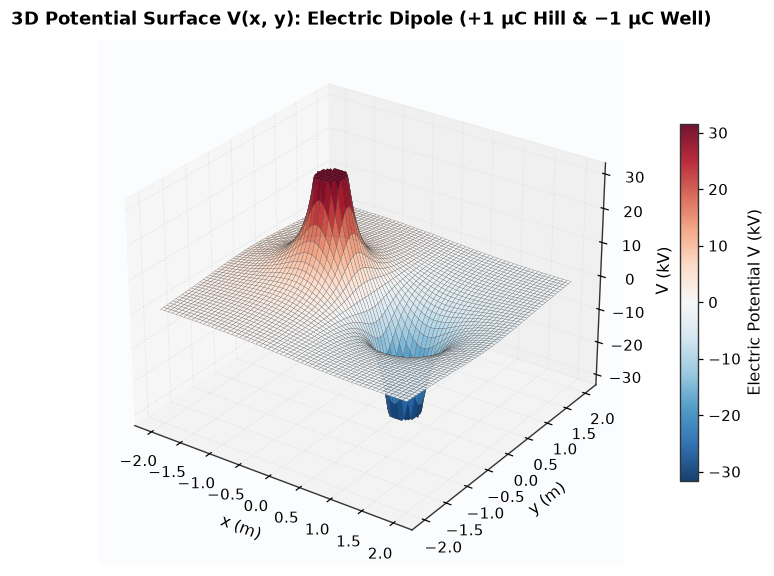

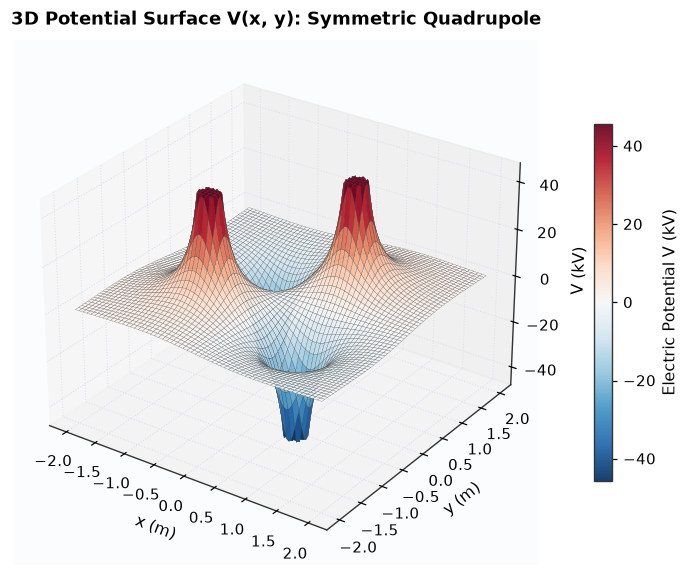

In [3]:
fig_dip_3d, _ = plot_potential_surface_3d(
    v_dip, title="3D Potential Surface V(x, y): Electric Dipole (+1 μC Hill & −1 μC Well)"
)
plt.show()

quad = get_preset_charges("symmetric_quadrupole", scale_q_uc=1.0, separation_m=1.4)
v_quad = electric_potential_2d(X, Y, quad)
fig_quad_3d, _ = plot_potential_surface_3d(
    v_quad, title="3D Potential Surface V(x, y): Symmetric Quadrupole"
)
plt.show()

---
## 3. Numerical Validation: Direct Coulomb Field vs. $-\nabla V$

On a discrete grid of spacing $h = \Delta x = \Delta y$, `numerical_field_from_potential()` computes $\mathbf{E}_{\text{num}} = -\nabla V$ via second-order central differences. Let us compare $\mathbf{E}_{\text{num}}$ directly against the analytical Coulomb vector field $\mathbf{E}_{\text{Coulomb}}$ across multiple grid resolutions.

Grid (N×N)   | dx (m)     | Median Rel Error   | Mean Rel Error   | RMS Angle Err (deg) 
--------------------------------------------------------------------------------------
51×51        | 0.0800     | 0.41095          % | 0.63390        % | 0.30668             
101×101      | 0.0400     | 0.09769          % | 0.15154        % | 0.07664             
201×201      | 0.0200     | 0.02380          % | 0.03684        % | 0.01886             
301×301      | 0.0133     | 0.01049          % | 0.01629        % | 0.00841             


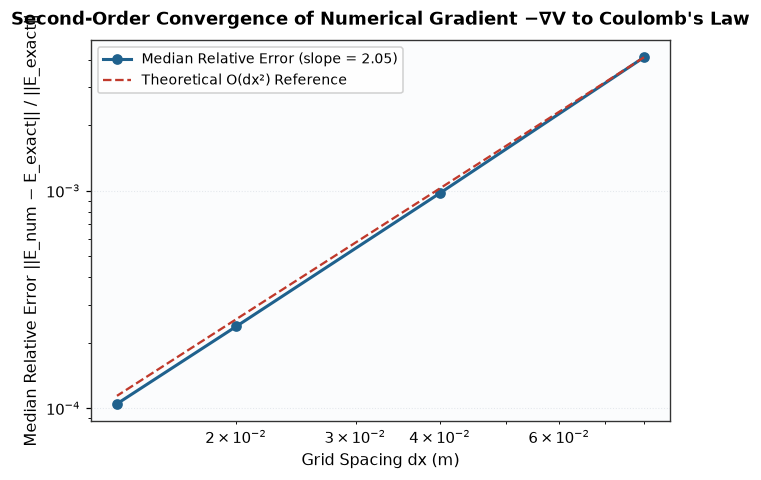

In [4]:
resolutions = [51, 101, 201, 301]
reports = [
    validate_potential_gradient_consistency(dipole, n_points=n, r_eval_min=0.35)
    for n in resolutions
]

print(f"{'Grid (N×N)':<12} | {'dx (m)':<10} | {'Median Rel Error':<18} | {'Mean Rel Error':<16} | {'RMS Angle Err (deg)':<20}")
print("-" * 86)
for r in reports:
    print(
        f"{f'{r.grid_resolution}×{r.grid_resolution}':<12} | "
        f"{r.grid_spacing_m:<10.4f} | "
        f"{r.median_rel_error * 100:<17.5f}% | "
        f"{r.mean_rel_error * 100:<15.5f}% | "
        f"{r.rms_angle_error_deg:<20.5f}"
    )

# Plot log-log convergence of finite-difference error vs grid spacing dx
dx_vals = np.array([r.grid_spacing_m for r in reports])
med_errs = np.array([r.median_rel_error for r in reports])
slope, _ = np.polyfit(np.log(dx_vals), np.log(med_errs), 1)

fig, ax = plt.subplots(figsize=(6.8, 4.5))
ax.loglog(dx_vals, med_errs, "o-", lw=2.0, color="#1f618d", label=f"Median Relative Error (slope = {slope:.2f})")
ax.loglog(dx_vals, med_errs[0] * (dx_vals / dx_vals[0]) ** 2, "--", color="#c0392b", label="Theoretical O(dx²) Reference")
ax.set_xlabel("Grid Spacing dx (m)")
ax.set_ylabel("Median Relative Error ||E_num − E_exact|| / ||E_exact||")
ax.set_title("Second-Order Convergence of Numerical Gradient −∇V to Coulomb's Law")
ax.legend()
plt.show()

### Interpretation
Away from the singularity cores ($r \ge 0.35\ \text{m}$), the discrepancy between $-\nabla V$ and the exact Coulomb field decreases quadratically with grid spacing ($\mathcal{O}(\Delta x^2)$, empirical log-log slope $\approx 2.0$), reaching a median relative error of $< 0.04\%$ and an RMS directional angle error of $< 0.02^\circ$ at $301 \times 301$ resolution.

---
## 4. Interactive Potential & Equipotential Explorer

In [5]:
import sys
from pathlib import Path
for _cand in (Path.cwd() / "src", Path.cwd().parent / "src"):
    if _cand.is_dir() and str(_cand.resolve()) not in sys.path:
        sys.path.insert(0, str(_cand.resolve()))
import numpy as np
import matplotlib.pyplot as plt
from invisible_physics import *

import ipywidgets as widgets
from IPython.display import display


def update_potential_view(
    preset: str = "dipole",
    scale_q_uc: float = 1.0,
    separation_m: float = 1.2,
    n_contours: int = 15,
) -> None:
    Xg, Yg = create_coordinate_grid((-2.0, 2.0), (-2.0, 2.0), n_points=101)
    charges = get_preset_charges(preset, scale_q_uc=scale_q_uc, separation_m=separation_m)
    v_res = electric_potential_2d(Xg, Yg, charges)
    f_res = electric_field_2d(Xg, Yg, charges)

    fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.5), constrained_layout=True)
    plot_electric_potential_landscape(
        v_res, charges, ax=axes[0], n_contours=n_contours,
        title=f"Potential V(r) & {n_contours} Equipotential Contours"
    )
    plot_combined_field_and_potential(
        f_res, v_res, charges, ax=axes[1], n_contours=n_contours,
        title="Orthogonality of E = −∇V and Equipotentials"
    )
    plt.show()


w_preset = widgets.Dropdown(
    options=["dipole", "two_like_positive", "unequal_opposite", "symmetric_quadrupole", "three_charge_triangle"],
    value="dipole",
    description="Preset:",
)
w_q = widgets.FloatSlider(value=1.0, min=0.2, max=5.0, step=0.2, description="Scale q (μC):")
w_sep = widgets.FloatSlider(value=1.2, min=0.4, max=2.4, step=0.1, description="Separation (m):")
w_cont = widgets.IntSlider(value=15, min=5, max=25, step=2, description="Contours:")

ui_pot = widgets.HBox([w_preset, w_q, w_sep, w_cont])
out_pot = widgets.interactive_output(
    update_potential_view,
    {"preset": w_preset, "scale_q_uc": w_q, "separation_m": w_sep, "n_contours": w_cont},
)
display(ui_pot, out_pot)

Output()

---
## Summary & Further Experiments
- **What we learned**: Scalar potential $V(\mathbf{r})$ sums algebraically and decays as $1/r$, making it simpler to compute than vector fields, while its negative gradient $-\nabla V$ recovers $\mathbf{E}(\mathbf{r})$ to second-order accuracy $\mathcal{O}(\Delta x^2)$ outside singularity cores.
- **Next steps**: Continue to [`03_magnetic_field_lab.ipynb`](03_magnetic_field_lab.ipynb) to investigate magnetostatic fields generated by steady electric currents.